# Compact MLP for baseline MCI progression prediction

Test a small feed-forward neural model against the existing Logistic Regression reference. Architecture: encoded input → 64 → 32 → 16 → 1 logit, GELU and dropout 0.3. Binary cross-entropy with logits, AdamW, learning rate 0.001, weight decay 0.001, batch size 32. These are proposed project settings, not an exact paper reproduction.

Written but not executed or tested by the assistant. Run the cells yourself. Original data, folds, and reports remain unchanged. No GPU is required.

## 1. Locate the project

Use the existing environment locally. In Colab, upload the files listed in `docs/deep_learning.md`; this cell mounts your Drive when you run it there.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None  # Set an absolute path here if automatic detection fails.
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'

ROOT = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/scripts/deep_models.py').is_file()), None)
if ROOT is None or not (ROOT / 'src/scripts/deep_models.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
print(ROOT)


/Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Install dependencies if needed

Skip this cell if already installed. Restart the kernel if requested, then rerun the path cell. This notebook does not install TabPFN.

In [2]:
requirements_file = str(ROOT / 'requirements-deep-learning.txt')
%pip install -r "{requirements_file}"



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Fix the protocol before fitting

Reuse the original five outer folds. Within each outer training set, use three inner folds to choose the training duration by validation loss, capped at 300 epochs with patience 25. Take the median inner best epoch, discard the inner models, and refit from scratch on the entire outer training set for that fixed duration. Scaling and one-hot encoding are fitted separately within every training split. Outer labels never choose epochs.

Run seeds 42, 43, and 44 without selecting the best one. Seed 42 is the prespecified primary single-model result. A separate `seed_mean` row averages the three probabilities and represents an ensemble. Do not treat seeds as independent participants. Threshold stays 0.5; there is no architecture or learning-rate search.

The three experiments are broader clinical (589), matched clinical (222), and matched fusion (222). Because previous results on these participants have been inspected, this remains exploratory.

In [3]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown
sys.path.insert(0, str(ROOT / 'src/scripts'))
from deep_models import load_data, run_deep_experiment

cfg = json.loads((ROOT / 'config/deep_learning.json').read_text())
KIND = 'mlp'
REPORT = ROOT / 'reports/modeling' / cfg['run_name'] / KIND
manifest, cohorts = load_data(cfg)
display(pd.DataFrame([{'experiment': name, 'participants': len(frame), 'converters': int(frame.label.sum()), 'nonconverters': int((frame.label == 0).sum())} for name, frame in cohorts.items()]))
print(json.dumps(cfg, indent=2))


,experiment,participants,converters,nonconverters
0,clinical_reference,589,216,373
1,matched_clinical,222,118,104
2,matched_fusion,222,118,104


{
  "baseline_run": "artifacts/modeling/complete_cases",
  "run_name": "deep_v1",
  "experiments": [
    "clinical_reference",
    "matched_clinical",
    "matched_fusion"
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "seed": 42,
  "inner_folds": 3,
  "threshold": 0.5,
  "bootstrap_repetitions": 1000,
  "device": "auto",
  "torch_threads": 1,
  "training": {
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "batch_size": 32,
    "max_epochs": 300,
    "patience": 25,
    "min_delta": 0.0001
  },
  "mlp": {
    "hidden_sizes": [
      64,
      32,
      16
    ],
    "dropout": 0.3
  },
  "resnet": {
    "width": 32,
    "hidden_width": 64,
    "blocks": 2,
    "dropout": 0.2
  },
  "tabpfn": {
    "package_version": "2.0.9",
    "model_path": "artifacts/pretrained/tabpfn-v2-classifier.ckpt",
    "checkpoint_url": "https://huggingface.co/Prior-Labs/TabPFN-v2-clf/resolve/758fe2b61e7665bb6fadd86fa6e0130a4a9b7dc4/tabpfn-v2-classifier.ckpt",
    "checkpoint_sha256": "f65a35685ae

## 4. Train

This performs 180 small neural fits at the default settings: three experiments × five outer folds × three seeds × (three inner fits + one refit). It also refits Logistic Regression in the current environment. The run can take substantially longer than the original classical run. Do not interrupt unless you intend to retain an incomplete run. Existing output directories are not overwritten.

In [4]:
results = run_deep_experiment(cfg, KIND)


mlp: clinical_reference, outer fold 1/5, seed 42
mlp: clinical_reference, outer fold 1/5, seed 43
mlp: clinical_reference, outer fold 1/5, seed 44
mlp: clinical_reference, outer fold 2/5, seed 42
mlp: clinical_reference, outer fold 2/5, seed 43
mlp: clinical_reference, outer fold 2/5, seed 44
mlp: clinical_reference, outer fold 3/5, seed 42
mlp: clinical_reference, outer fold 3/5, seed 43
mlp: clinical_reference, outer fold 3/5, seed 44
mlp: clinical_reference, outer fold 4/5, seed 42
mlp: clinical_reference, outer fold 4/5, seed 43
mlp: clinical_reference, outer fold 4/5, seed 44
mlp: clinical_reference, outer fold 5/5, seed 42
mlp: clinical_reference, outer fold 5/5, seed 43
mlp: clinical_reference, outer fold 5/5, seed 44
mlp: matched_clinical, outer fold 1/5, seed 42
mlp: matched_clinical, outer fold 1/5, seed 43
mlp: matched_clinical, outer fold 1/5, seed 44
mlp: matched_clinical, outer fold 2/5, seed 42
mlp: matched_clinical, outer fold 2/5, seed 43
mlp: matched_clinical, outer f

## 5. Results

Skip the training cell when revisiting a completed run. Compare models within each cohort. Higher accuracy/AUROC/AP and lower Brier are better. Check sensitivity and specificity, not just accuracy.

,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,mlp_seed42,589,83.9%,81.0%,73.1%,90.1%,76.9%,81.6%,0.910,0.852,0.114
2,clinical_reference,mlp_seed43,589,84.6%,82.4%,73.6%,90.9%,77.8%,82.2%,0.910,0.851,0.113
3,clinical_reference,mlp_seed44,589,84.6%,81.1%,75.5%,89.8%,78.2%,82.6%,0.911,0.851,0.112
4,clinical_reference,mlp_seed_mean,589,84.0%,81.4%,73.1%,90.3%,77.1%,81.7%,0.911,0.852,0.112
5,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
6,matched_clinical,mlp_seed42,222,80.2%,81.4%,81.4%,78.8%,81.4%,80.1%,0.884,0.897,0.142
7,matched_clinical,mlp_seed43,222,80.2%,80.3%,83.1%,76.9%,81.7%,80.0%,0.886,0.904,0.138
8,matched_clinical,mlp_seed44,222,82.0%,83.1%,83.1%,80.8%,83.1%,81.9%,0.899,0.916,0.130
9,matched_clinical,mlp_seed_mean,222,80.6%,81.0%,83.1%,77.9%,82.0%,80.5%,0.894,0.910,0.135


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,mlp_seed42,336,37,58,158
2,clinical_reference,mlp_seed43,339,34,57,159
3,clinical_reference,mlp_seed44,335,38,53,163
4,clinical_reference,mlp_seed_mean,337,36,58,158
5,matched_clinical,logistic_regression,82,22,21,97
6,matched_clinical,mlp_seed42,82,22,22,96
7,matched_clinical,mlp_seed43,80,24,20,98
8,matched_clinical,mlp_seed44,84,20,20,98
9,matched_clinical,mlp_seed_mean,81,23,20,98


,experiment,metric,mean,std,min,max
0,clinical_reference,accuracy,0.8432,0.0039,0.8387,0.8455
1,clinical_reference,auroc,0.9102,0.0007,0.9097,0.9110
2,clinical_reference,average_precision,0.8513,0.0004,0.8508,0.8516
3,clinical_reference,brier_score,0.1127,0.0009,0.1118,0.1137
4,clinical_reference,sensitivity,0.7407,0.0122,0.7315,0.7546
5,clinical_reference,specificity,0.9026,0.0056,0.8981,0.9088
6,matched_clinical,accuracy,0.8078,0.0104,0.8018,0.8198
7,matched_clinical,auroc,0.8895,0.0079,0.8836,0.8985
8,matched_clinical,average_precision,0.9056,0.0099,0.8968,0.9164
9,matched_clinical,brier_score,0.1366,0.0065,0.1296,0.1423


,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,mlp_seed42,logistic_regression,auroc,-0.0023,-0.0099,0.0054,1000
1,clinical_reference,mlp_seed42,logistic_regression,average_precision,-0.0004,-0.0151,0.0178,1000
2,clinical_reference,mlp_seed42,logistic_regression,brier_score,0.0040,-0.0011,0.0090,1000
3,clinical_reference,mlp_seed42,logistic_regression,accuracy,-0.0051,-0.0204,0.0102,1000
4,clinical_reference,mlp_seed_mean,logistic_regression,auroc,-0.0010,-0.0077,0.0056,1000
5,clinical_reference,mlp_seed_mean,logistic_regression,average_precision,0.0004,-0.0130,0.0174,1000
6,clinical_reference,mlp_seed_mean,logistic_regression,brier_score,0.0024,-0.0023,0.0067,1000
7,clinical_reference,mlp_seed_mean,logistic_regression,accuracy,-0.0034,-0.0170,0.0102,1000
8,matched_clinical,mlp_seed42,logistic_regression,auroc,-0.0146,-0.0328,0.0031,1000
9,matched_clinical,mlp_seed42,logistic_regression,average_precision,-0.0204,-0.0431,-0.0029,1000


,experiment,outer_fold,seed,inner_best_epochs,refit_epochs,encoded_input_columns,trainable_parameters
0,clinical_reference,1,42,"[9, 14, 15]",14,18,3841
1,clinical_reference,1,43,"[15, 13, 19]",15,18,3841
2,clinical_reference,1,44,"[9, 15, 16]",15,18,3841
3,clinical_reference,2,42,"[26, 12, 16]",16,18,3841
4,clinical_reference,2,43,"[25, 16, 17]",17,18,3841
5,clinical_reference,2,44,"[16, 13, 15]",15,18,3841
6,clinical_reference,3,42,"[10, 14, 24]",14,18,3841
7,clinical_reference,3,43,"[13, 16, 24]",16,18,3841
8,clinical_reference,3,44,"[16, 16, 19]",16,18,3841
9,clinical_reference,4,42,"[9, 17, 15]",15,18,3841


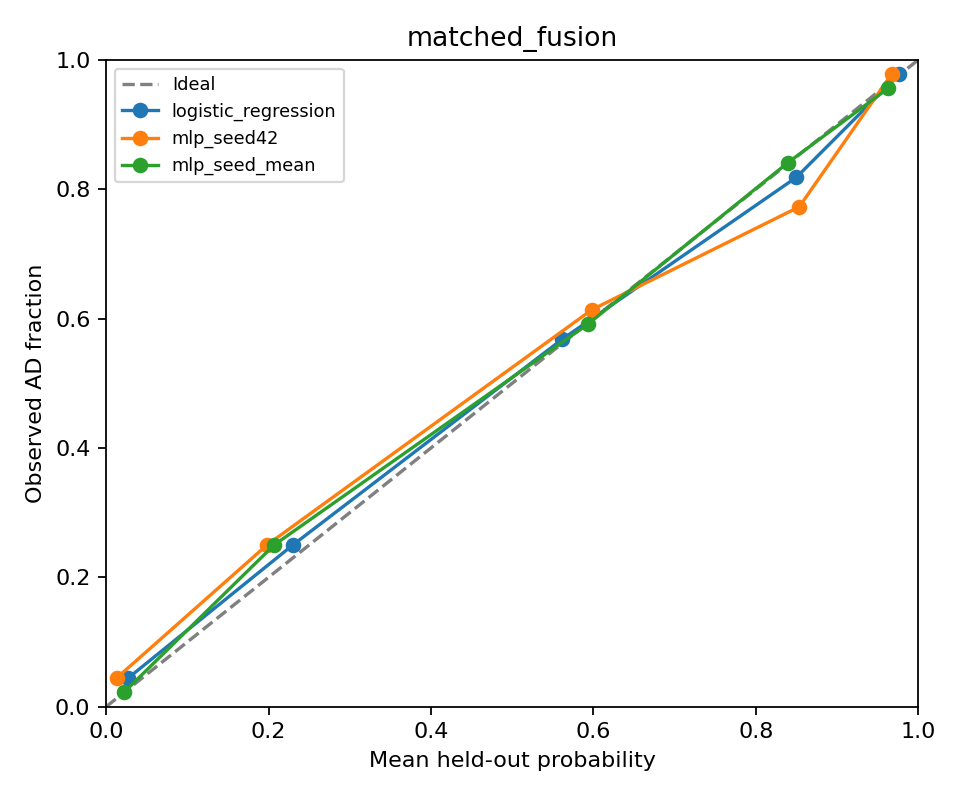

# Exploratory mlp results

| Experiment | Model | N | Accuracy | AUROC | AP | Brier |
|---|---|---:|---:|---:|---:|---:|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 |
| clinical_reference | mlp_seed42 | 589 | 83.9% | 0.910 | 0.852 | 0.114 |
| clinical_reference | mlp_seed43 | 589 | 84.6% | 0.910 | 0.851 | 0.113 |
| clinical_reference | mlp_seed44 | 589 | 84.6% | 0.911 | 0.851 | 0.112 |
| clinical_reference | mlp_seed_mean | 589 | 84.0% | 0.911 | 0.852 | 0.112 |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 |
| matched_clinical | mlp_seed42 | 222 | 80.2% | 0.884 | 0.897 | 0.142 |
| matched_clinical | mlp_seed43 | 222 | 80.2% | 0.886 | 0.904 | 0.138 |
| matched_clinical | mlp_seed44 | 222 | 82.0% | 0.899 | 0.916 | 0.130 |
| matched_clinical | mlp_seed_mean | 222 | 80.6% | 0.894 | 0.910 | 0.135 |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 |
| matched_fusion | mlp_seed42 | 222 | 81.1% | 0.895 | 0.905 | 0.130 |
| matched_fusion | mlp_seed43 | 222 | 82.0% | 0.895 | 0.890 | 0.130 |
| matched_fusion | mlp_seed44 | 222 | 79.3% | 0.895 | 0.909 | 0.134 |
| matched_fusion | mlp_seed_mean | 222 | 80.6% | 0.896 | 0.906 | 0.130 |

## Interpretation

- The first configured seed (42) is the prespecified single-model result, not the best seed.
- The seed_mean row averages probabilities from all configured seeds. It is a separate seed ensemble, not the mean of the accuracy scores.
- Seed variability describes repeated fitting on the same participants. Seeds are not independent patient samples.
- The fixed Logistic Regression reference is refitted in the same environment on identical outer folds.
- Architecture, optimizer settings, and threshold were fixed. MLP/ResNet inner folds select training duration only; final models refit on the full outer training set.
- TabPFN uses a pinned pretrained model and no task-specific gradient optimization; this is not training a transformer from scratch.
- AP is non-interpolated average precision. Metric CSV rates use 0-1 scales; confusion counts are counts.
- Paired intervals condition on saved predictions, omit full retraining uncertainty, and are not adjusted for multiple comparisons.
- Previously inspected cohorts make this exploratory. Do not select the best result and call it independent confirmation.
- Broader clinical and matched cohorts are different populations. The matched cohort is ADNI1 only; labels remain provisional.
- Complete-case selection, unresolved outcomes, unavailable MRI/CSF comparisons, and no external validation remain limitations.


In [5]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])
display(pd.read_csv(REPORT / 'seed_variability.csv').round(4))
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(pd.read_csv(REPORT / 'training_epochs.csv'))
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))
display(Markdown((REPORT / 'results.md').read_text()))


## Interpretation

Paired differences are new model minus same-run Logistic Regression. Multiply accuracy differences by 100 for percentage points. Intervals that span zero do not establish an improvement under this conditional bootstrap. The bootstrap does not include all retraining uncertainty and is not adjusted for multiple comparisons.

`training_epochs.csv` records actual parameter counts and encoded input widths. One-hot encoding may increase the width beyond the 17/18 original columns. `learning_curves.csv` contains inner validation curves and outer refit training curves (inner_fold=0); no outer test loss is used to stop training.

Share metrics, seed variability, paired comparisons, and selected epochs before changing settings. Neural SHAP is not implemented here; the earlier SHAP results apply only to their original models. Next notebook: `04_tabular_resnet.ipynb`.